# Systemy AI – Laboratorium 4

## 1. Wczytanie danych


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

df = sns.load_dataset("penguins")
print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


Etykieta: `species` opisuje gatunek tekstem.

---
## 2. EDA – eksploracyjna analiza danych

In [5]:
# rozkład etykiety
print(df["species"].value_counts(normalize=True).round(3))

# braki w procentach (tylko kolumny z brakami)
missing = df.isna().mean().mul(100).round(1)
missing[missing > 0]

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64


,0
bill_length_mm,0.6
bill_depth_mm,0.6
flipper_length_mm,0.6
body_mass_g,0.6
sex,3.2


In [6]:
# skale i skośność cech liczbowych
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(df[num_cols].describe().round(1))
print("\nskośność:", df[num_cols].skew().round(2).to_dict())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

skośność: {'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


In [7]:
# Zależność etykiety (species) od wyspy (island)
print("Rozkład gatunków na poszczególnych wyspach (liczbowo):")
display(pd.crosstab(df["island"], df["species"]))

print("\nRozkład gatunków na poszczególnych wyspach (procentowo w ramach wyspy):")
display(pd.crosstab(df["island"], df["species"], normalize="index").round(3))

print("\nŚrednie wartości cech liczbowych dla każdego gatunku:")
display(df.groupby("species")[num_cols].mean().round(1))

Rozkład gatunków na poszczególnych wyspach (liczbowo):


species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,124
Dream,56,68,0
Torgersen,52,0,0



Rozkład gatunków na poszczególnych wyspach (procentowo w ramach wyspy):


species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,0.262,0.000,0.738
Dream,0.452,0.548,0.000
Torgersen,1.000,0.000,0.000



Średnie wartości cech liczbowych dla każdego gatunku:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.0,3700.7
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.5,15.0,217.2,5076.0


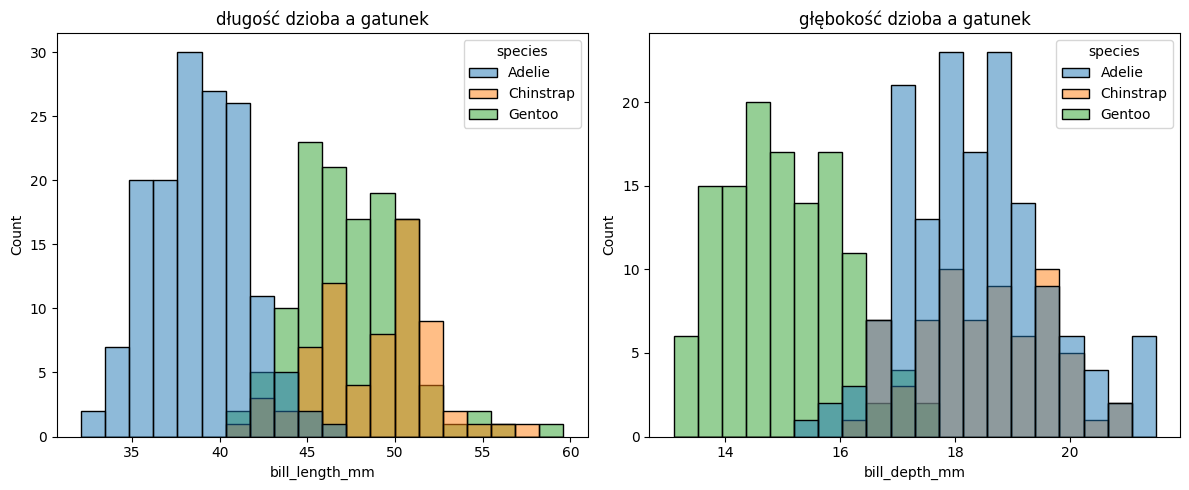

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="bill_length_mm", hue="species", bins=20, ax=axes[0])
axes[0].set_title("długość dzioba a gatunek")
sns.histplot(data=df, x="bill_depth_mm", hue="species", bins=20, ax=axes[1])
axes[1].set_title("głębokość dzioba a gatunek")

fig.tight_layout()
plt.show()

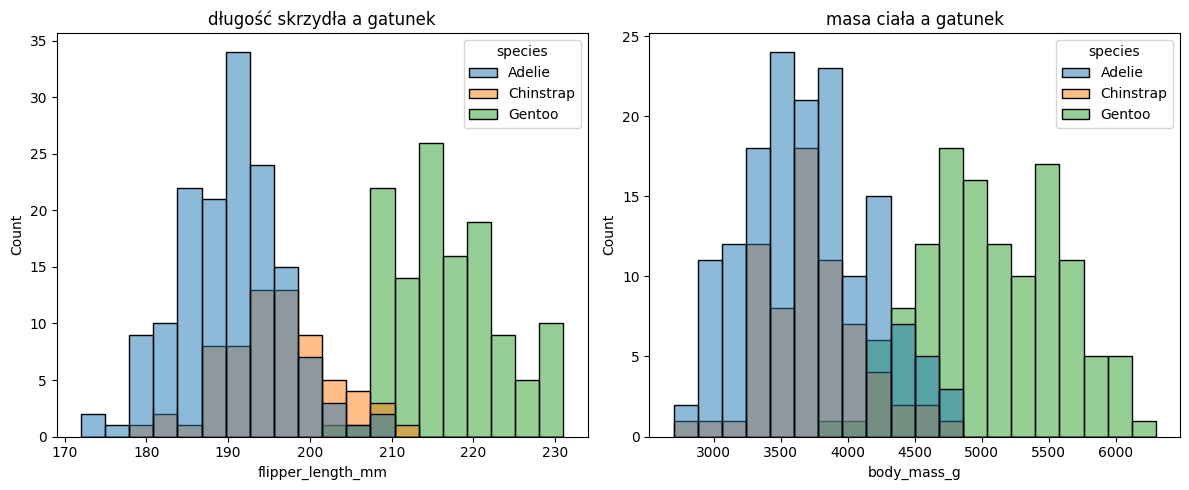

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="flipper_length_mm", hue="species", bins=20, ax=axes[0])
axes[0].set_title("długość skrzydła a gatunek")
sns.histplot(data=df, x="body_mass_g", hue="species", bins=20, ax=axes[1])
axes[1].set_title("masa ciała a gatunek")
fig.tight_layout()
plt.show()

**Wnioski dla dalszych działań:
- klasy niezbalansowane (Adelie 44,2% \ Gentoo 36% \ Chinstrap 19,8%)
- Braki w etykietach <1% → uzupełnienie najczęstszą wartością
- `species` `island` i `sex` do zakodowania z powodu typu object
- rózne skale `flipper_length_mm` `body_mass_g` `bill_length_mm` i `bill_depth_mm` → strandaryzacja


---
## 3. Podział train / test

In [9]:
features = [ "island",	"bill_length_mm",	"bill_depth_mm",	"flipper_length_mm",	"body_mass_g",	"sex"]
target = "species"

X_train, X_test, y_train, y_test = train_test_split(
    df[features], df[target],
    test_size=0.25,        # 25% do testu
    stratify=df[target],   # ten sam odsetek ocalałych w obu częściach
    random_state=42,       # powtarzalny podział
)
print(X_train.shape, X_test.shape)
print(f"gatunki: train {y_train}, test {y_test}")

(258, 6) (86, 6)
gatunki: train 291       Gentoo
144       Adelie
212    Chinstrap
45        Adelie
78        Adelie
         ...    
10        Adelie
333       Gentoo
75        Adelie
82        Adelie
160    Chinstrap
Name: species, Length: 258, dtype: object, test 236       Gentoo
230       Gentoo
151       Adelie
173    Chinstrap
174    Chinstrap
         ...    
180    Chinstrap
287       Gentoo
116       Adelie
288       Gentoo
79        Adelie
Name: species, Length: 86, dtype: object


## 4. Przygotowanie danych: jak działa scikit-learn

In [10]:
imputer = SimpleImputer(strategy="most_frequent")
imputer.fit(X_train)
X_train_imputed = imputer.transform(X_train)
X_train_imputed = pd.DataFrame(X_train_imputed, columns=X_train.columns)
X_train_imputed.head

print(X_train_imputed.isna().sum())
# sprawdzenie czy pozostały jakieś braki

island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


### 4b. Kodowanie zmiennych tekstowych: `OneHotEncoder`

In [11]:
try:
  LogisticRegression().fit(X_train_imputed, y_train)
except ValueError as e:
  print("ValueError ", e)

ValueError  could not convert string to float: 'Biscoe'


In [12]:
encoder = OneHotEncoder(handle_unknown="ignore")
encoder.fit(X_train_imputed)
X_train_encoded = encoder.transform(X_train_imputed)
print(X_train_encoded.shape)

(258, 371)


### 4c. Skalowanie: `StandardScaler`

In [16]:
# Wybieramy już uzupełnione kolumny z gotowej ramki X_train_imputed
flipper_mass_bill = X_train_imputed[["flipper_length_mm", "body_mass_g", "bill_length_mm", "bill_depth_mm"]]

scaler = StandardScaler()
scaler.fit(flipper_mass_bill)
print("Średnie cech:", scaler.mean_)
print("Odchylenia standardowe (skala):", scaler.scale_)

Średnie cech: [ 200.84883721 4212.20930233   44.16627907   17.16046512]
Odchylenia standardowe (skala): [ 13.90180188 799.20997982   5.53373608   2.01274692]


### 4d. Wszystko razem: `ColumnTransformer` + `Pipeline`

In [17]:
num_features = ["flipper_length_mm", "body_mass_g", "bill_length_mm", "bill_depth_mm"]
cat_features = ["island", "sex"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", make_pipeline(SimpleImputer(strategy="mean"), StandardScaler()), num_features),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat_features),
    ]

)

model = make_pipeline(preprocessor, LogisticRegression(max_iter=1000))
model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer()),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['flipper_length_mm',
                                                   'body_mass_g',
                                                   'bill_length_mm',
                                                   'bill_depth_mm']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['island', 'sex'])])),
                ('logisticregression', LogisticRegression(max_iter=1000))])

---
## 5. Trenowanie

In [18]:
model.fit(X_train, y_train)

nums = model.named_steps["columntransformer"].named_transformers_["num"]
print("Średnie:", nums.named_steps["simpleimputer"].statistics_)
print("Odchylenia standardowe:", nums.named_steps["standardscaler"].scale_)

names = model.named_steps["columntransformer"].get_feature_names_out()
weights = pd.Series(model.named_steps["logisticregression"].coef_[0], index=names).sort_values()
weights.round(3)

Średnie: [ 200.89453125 4216.2109375    44.11679688   17.16171875]
Odchylenia standardowe: [ 13.89218624 797.92663641   5.50534546   2.01269695]


,0
num__bill_length_mm,-2.277
num__flipper_length_mm,-0.600
cat__island_Dream,-0.551
cat__sex_Female,-0.444
cat__island_Biscoe,-0.094
num__body_mass_g,-0.008
cat__sex_Male,0.451
cat__island_Torgersen,0.652
num__bill_depth_mm,0.977


---
## 6. Predykcja

In [20]:
y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

preview = X_test.head(5).copy()
preview["gatunek"] = proba[:5].round(2)
preview["predykcja"] = y_pred[:5]
preview["prawda"] = y_test.head(5).values
preview

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,gatunek,predykcja,prawda
236,Biscoe,42.0,13.5,210.0,4150.0,Female,0.00,Gentoo,Gentoo
230,Biscoe,40.9,13.7,214.0,4650.0,Female,0.00,Gentoo,Gentoo
151,Dream,41.5,18.5,201.0,4000.0,Male,0.07,Adelie,Adelie
173,Dream,48.5,17.5,191.0,3400.0,Male,0.96,Chinstrap,Chinstrap
174,Dream,43.2,16.6,187.0,2900.0,Female,0.88,Chinstrap,Chinstrap


---
## 7. Ewaluacja


In [29]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

# Prosta reguła klasyfikacji oparta o wyspę:
# Jeśli wyspa to Biscoe -> Gentoo, w przeciwnym wypadku najczęstszy gatunek (Adelie)
rule_predictions = np.where(X_test["island"] == "Biscoe", "Gentoo", "Adelie")

results = pd.Series({
    "baseline (zawsze Adelie)": baseline.score(X_test, y_test),
    "reguła: wyspa Biscoe → Gentoo, reszta → Adelie": (rule_predictions == y_test).mean(),
    "pipeline – train": model.score(X_train, y_train),
    "pipeline – test": model.score(X_test, y_test),
})
results.round(3)

,0
baseline (zawsze Adelie),0.442
"reguła: wyspa Biscoe → Gentoo, reszta → Adelie",0.651
pipeline – train,0.992
pipeline – test,1.000


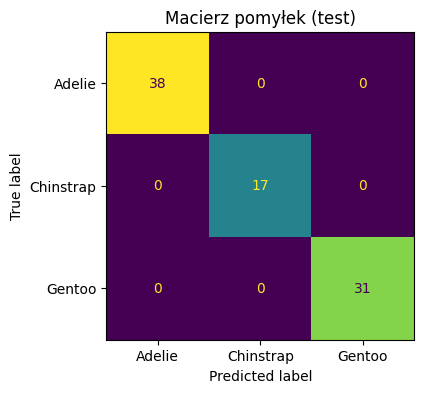

              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        38
   Chinstrap      1.000     1.000     1.000        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          1.000        86
   macro avg      1.000     1.000     1.000        86
weighted avg      1.000     1.000     1.000        86



In [28]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Adelie", "Chinstrap","Gentoo"]).plot(ax=ax, colorbar=False)
ax.set_title("Macierz pomyłek (test)")
plt.show()

print(classification_report(y_test, y_pred, target_names=["Adelie", "Chinstrap","Gentoo"], digits=3))

---
## 8. Iteracja

In [40]:
def build_model(num, cat, add_indicator=False):
    prep = ColumnTransformer([
        ("liczby", make_pipeline(SimpleImputer(strategy="median", add_indicator=add_indicator), StandardScaler()), num),
        ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat),
    ])
    return make_pipeline(prep, LogisticRegression())


variants = {
    "pełny": build_model(num_features, cat_features),
    "+ flaga braku wieku": build_model(num_features, cat_features, add_indicator=True),
    "bez wyspy": build_model(num_features, ["sex"]),
    "bez płci": build_model(num_features, ["island"]),
    "bez płci i wyspy": build_model(num_features, []),
    "sama płeć": build_model([], ["sex"]),
    "sama wyspa": build_model([], ["island"]),

}
pd.Series({nazwa: m.fit(X_train, y_train).score(X_test, y_test) for nazwa, m in variants.items()}).round(3)

,0
pełny,1.000
+ flaga braku wieku,1.000
bez wyspy,1.000
bez płci,1.000
bez płci i wyspy,1.000
sama płeć,0.442
sama wyspa,0.686
